# Philadelphia Crime Class Grouping

## 1. Introduction

The combined Philadelphia dataset contains 32 original `text_general_code` categories. Some labels describe closely related offenses, while very fine-grained classes can be extremely sparse; `Homicide - Gross Negligence` is represented by one record. Following the teacher’s project-specific requirement, this notebook consolidates semantically related labels into broader, interpretable categories before a later classification experiment.

**The original dataset is preserved unchanged. Grouping is performed only in an analysis/modeling copy.** No model is trained in this notebook.

### Base-paper methodology and project-specific modification

The base paper motivates crime-type classification using Philadelphia incident attributes. The semantic grouping in this notebook is a separate project-specific modification requested by the teacher. The exact categories below are not attributed to the base paper.

## 2. Load and Verify the Dataset

Load the canonical combined dataset with a project-relative path, then confirm the expected target and inspect its dimensions and sample.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedShuffleSplit

try:
    from _bootstrap import ensure_project_root
except ModuleNotFoundError:
    from notebooks._bootstrap import ensure_project_root
project_root = ensure_project_root()
from src.config import TARGET_ORIGINAL, TARGET_GROUPED
from src.data_loader import (load_combined_philadelphia_data,
                             load_grouped_philadelphia_data,
                             load_class_group_mapping)
from src.data_validation import (get_class_distribution, validate_dataframe,
                                 validate_target)

sns.set_theme(style="whitegrid", context="notebook")
df = load_combined_philadelphia_data(low_memory=False)
target = TARGET_ORIGINAL
validate_dataframe(df, required_columns=[target])
target_summary = validate_target(df, target)
assert target_summary["class_count"] == 32, target_summary
print("Loaded original dataset:", df.shape)
print("Original classes:", target_summary["class_count"])


Loaded original dataset: (736033, 20)
Original classes: 32


## 3. Original Class Distribution and Rare Labels

The full original distribution is calculated before assigning any groups. Rare classes are identified for audit purposes only; no rows or labels are removed.

,Original Crime Type,Count,Percentage
0,Thefts,127055,17.2621
1,Other Assaults,119583,16.2470
2,All Other Offenses,95265,12.9430
3,Vandalism/Criminal Mischief,71977,9.7790
4,Theft from Vehicle,67615,9.1864
5,Fraud,46603,6.3316
6,Narcotic / Drug Law Violations,33032,4.4878
7,Aggravated Assault No Firearm,26504,3.6009
8,Motor Vehicle Theft,25402,3.4512
9,Burglary Residential,20944,2.8455


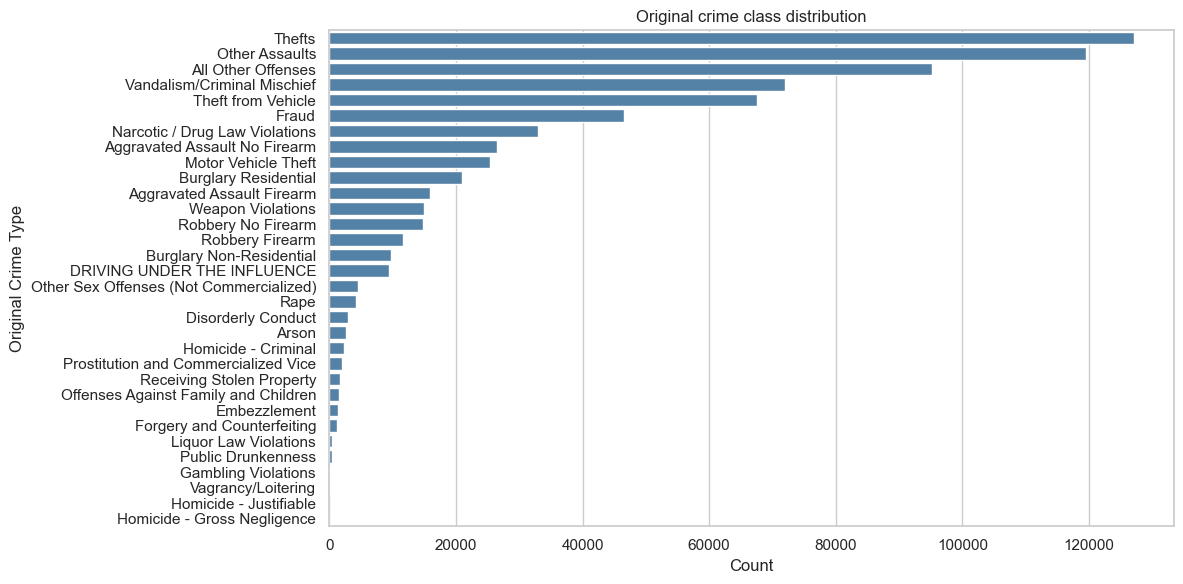

In [2]:
original_distribution = get_class_distribution(df, target).rename(columns={"Class": "Original Crime Type", "Count": "Count", "Percentage": "Percentage"})
original_counts = original_distribution.set_index("Original Crime Type")["Count"]
display(original_distribution)
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=original_distribution, x="Count", y="Original Crime Type", ax=ax, color="steelblue")
ax.set_title("Original crime class distribution")
plt.tight_layout()
plt.show()


## 4. Inspect the Actual Crime Labels

The following table displays every label exactly as recorded, with its observed count. These observed values are the complete input domain for the explicit mapping below.

In [3]:
actual_labels = sorted(df[target].unique().tolist())
display(pd.DataFrame({"Actual crime label": actual_labels,
                      "Count": [int(original_counts[label]) for label in actual_labels]}))
print(f"Unique labels listed: {len(actual_labels)}")


,Actual crime label,Count
0,Aggravated Assault Firearm,15925
1,Aggravated Assault No Firearm,26504
2,All Other Offenses,95265
3,Arson,2578
4,Burglary Non-Residential,9798
5,Burglary Residential,20944
6,DRIVING UNDER THE INFLUENCE,9470
7,Disorderly Conduct,3022
8,Embezzlement,1357
9,Forgery and Counterfeiting,1280


Unique labels listed: 32


## 5. Semantic Grouping Analysis

Labels are grouped by the offense described in their wording, not by `ucr_general`, class frequency, or expected model performance. Distinctions are retained when the offense type is substantively different. For example, homicide, assault, robbery, burglary, theft, financial deception, property damage, weapons, drug law, sexual/commercial-sex, family/child, public-order, impaired-driving, and residual “all other” offenses remain distinct broad concepts.

## 6. Complete Explicit Mapping and Rationale

Each source label is assigned exactly one broader category. The rationale describes the semantic basis for the assignment. The rare `Homicide - Gross Negligence` label is grouped with homicide-related offenses because the label explicitly denotes a homicide classification; it is not given a singleton category.

In [4]:
grouping_details = {
    "Aggravated Assault Firearm": ("Assault-Related Offenses", "An aggravated assault offense; grouped with other assault labels, while firearm distinction is retained in the original label."),
    "Aggravated Assault No Firearm": ("Assault-Related Offenses", "An aggravated assault offense; grouped with other assault labels, while firearm distinction is retained in the original label."),
    "Other Assaults": ("Assault-Related Offenses", "An assault offense and semantically related to the aggravated-assault categories."),
    "Homicide - Criminal": ("Homicide-Related Offenses", "Explicit criminal homicide classification."),
    "Homicide - Justifiable": ("Homicide-Related Offenses", "Explicit homicide classification; justifiability remains a distinction in the original label."),
    "Homicide - Gross Negligence": ("Homicide-Related Offenses", "Explicit homicide classification; grouped with the broader homicide family despite its single-record frequency."),
    "Robbery Firearm": ("Robbery Offenses", "Robbery offense; firearm subtype retained in the source label."),
    "Robbery No Firearm": ("Robbery Offenses", "Robbery offense; firearm subtype retained in the source label."),
    "Burglary Residential": ("Burglary Offenses", "Residential subtype of burglary."),
    "Burglary Non-Residential": ("Burglary Offenses", "Non-residential subtype of burglary."),
    "Thefts": ("Theft and Stolen-Property Offenses", "Direct theft offense."),
    "Theft from Vehicle": ("Theft and Stolen-Property Offenses", "Theft offense distinguished by a vehicle as the property source."),
    "Motor Vehicle Theft": ("Theft and Stolen-Property Offenses", "Theft offense involving a motor vehicle."),
    "Receiving Stolen Property": ("Theft and Stolen-Property Offenses", "Offense involving receipt of property known or treated as stolen; related to stolen-property acquisition."),
    "Fraud": ("Fraud and Financial-Deception Offenses", "Direct fraud/deception offense."),
    "Forgery and Counterfeiting": ("Fraud and Financial-Deception Offenses", "Document or currency deception offense, semantically related to fraud."),
    "Embezzlement": ("Fraud and Financial-Deception Offenses", "Deceptive appropriation of entrusted property; grouped with financial deception offenses."),
    "Vandalism/Criminal Mischief": ("Property-Damage and Fire Offenses", "Intentional property damage offense."),
    "Arson": ("Property-Damage and Fire Offenses", "Fire-setting offense with property-damage implications."),
    "Weapon Violations": ("Weapon Offenses", "Weapons-related offense; retained as a distinct broad category."),
    "Narcotic / Drug Law Violations": ("Drug-Law Offenses", "Explicit violation of narcotics or drug laws."),
    "Rape": ("Sexual and Commercial-Sex Offenses", "Sexual offense; grouped with other sexual-offense labels."),
    "Other Sex Offenses (Not Commercialized)": ("Sexual and Commercial-Sex Offenses", "Explicit non-commercial sexual-offense category."),
    "Prostitution and Commercialized Vice": ("Sexual and Commercial-Sex Offenses", "Commercialized sexual conduct category; broader group preserves this relation while the exact subtype remains in the original label."),
    "Offenses Against Family and Children": ("Family and Child-Related Offenses", "The label explicitly identifies family or child-related offenses; retained as its own interpretable category."),
    "Disorderly Conduct": ("Public-Order Offenses", "Conduct classified as disorderly/public-order behavior."),
    "Gambling Violations": ("Public-Order Offenses", "Regulatory offense involving gambling; grouped with other public-order/regulatory labels."),
    "Liquor Law Violations": ("Public-Order Offenses", "Alcohol-law regulatory offense; grouped with public-order/regulatory violations."),
    "Public Drunkenness": ("Public-Order Offenses", "Public conduct offense associated with intoxication."),
    "Vagrancy/Loitering": ("Public-Order Offenses", "Public-order conduct category."),
    "DRIVING UNDER THE INFLUENCE": ("Impaired-Driving Offenses", "Driving offense involving impairment; distinguished from general public-order and alcohol-law offenses."),
    "All Other Offenses": ("Other / Unspecified Offenses", "Residual source category with no more specific semantic description in its label; retained as residual."),
}

crime_group_mapping = {label: details[0] for label, details in grouping_details.items()}
grouping_rationale = {label: details[1] for label, details in grouping_details.items()}
print("Mapping dictionary entries:", len(crime_group_mapping))
print("Number of observed original labels:", len(actual_labels))


Mapping dictionary entries: 32
Number of observed original labels: 32


### Grouping rules applied

1. Grouping follows semantic similarity of the recorded offense labels.
2. Broad categories remain criminologically interpretable.
3. Frequency is reported but does not determine a grouping.
4. Unrelated offenses are not combined to enlarge classes.
5. Model performance is not used to choose categories.
6. The mapping is explicit and deterministic.
7. Each observed source label must appear exactly once.
8. Original labels remain available for traceability.

## 7. Validate Mapping Completeness

Before applying the mapping, verify unique keys, exact correspondence to the observed 32 labels, and one assignment per source class. Any mismatch stops execution.

In [5]:
observed_set = set(df[target].unique())
mapping_set = set(crime_group_mapping.keys())
missing_labels = observed_set - mapping_set
extra_labels = mapping_set - observed_set
duplicate_mapping_keys = len(crime_group_mapping) != len(set(crime_group_mapping))
assert not duplicate_mapping_keys, "Duplicate mapping keys detected."
assert not missing_labels and not extra_labels, f"Mapping mismatch; missing={missing_labels}, extra={extra_labels}"
assert len(crime_group_mapping) == len(observed_set), "Mapping size does not match the unique observed label count."
print("Mapping validation passed.")
print(f"Original classes: {len(observed_set)} | Mapping keys: {len(crime_group_mapping)} | Mapping complete: {100.0:.1f}%")

validate_target(df, target, expected_classes=32)


Mapping validation passed.
Original classes: 32 | Mapping keys: 32 | Mapping complete: 100.0%


{'target': 'text_general_code',
 'class_count': 32,
 'classes': ['Homicide - Criminal',
  'Homicide - Justifiable',
  'Robbery No Firearm',
  'Aggravated Assault No Firearm',
  'Robbery Firearm',
  'Aggravated Assault Firearm',
  'Burglary Residential',
  'Thefts',
  'Rape',
  'Burglary Non-Residential',
  'Theft from Vehicle',
  'Narcotic / Drug Law Violations',
  'Weapon Violations',
  'All Other Offenses',
  'Other Assaults',
  'DRIVING UNDER THE INFLUENCE',
  'Arson',
  'Embezzlement',
  'Liquor Law Violations',
  'Fraud',
  'Other Sex Offenses (Not Commercialized)',
  'Prostitution and Commercialized Vice',
  'Vandalism/Criminal Mischief',
  'Disorderly Conduct',
  'Public Drunkenness',
  'Offenses Against Family and Children',
  'Gambling Violations',
  'Receiving Stolen Property',
  'Forgery and Counterfeiting',
  'Vagrancy/Loitering',
  'Motor Vehicle Theft',
  'Homicide - Gross Negligence'],
 'missing_count': 0}

## 8. Create the Mapping Table and Analysis Copy

The mapping table contains exactly one row per original class, with its original count, grouped category, and rationale. `df_grouped` is an in-memory copy that retains both the original target and the new grouped target.

In [6]:
mapping_table = pd.DataFrame({
    "Original Crime Type": list(crime_group_mapping.keys()),
    "Original Count": [int(original_counts[label]) for label in crime_group_mapping],
    "Grouped Crime Category": list(crime_group_mapping.values()),
    "Grouping Rationale": [grouping_rationale[label] for label in crime_group_mapping],
}).sort_values(["Grouped Crime Category", "Original Crime Type"]).reset_index(drop=True)
assert len(mapping_table) == 32
display(mapping_table)

df_grouped = df.copy()
original_target_before = df_grouped[target].copy()
df_grouped["crime_group"] = df_grouped[target].map(crime_group_mapping)
unmapped_records = int(df_grouped["crime_group"].isna().sum())
assert unmapped_records == 0, f"Found {unmapped_records} unmapped records."
assert df_grouped[target].equals(original_target_before), "Original target labels changed in the analysis copy."
print("Grouped copy shape:", df_grouped.shape)
print("Unmapped records:", unmapped_records)
print("Null crime_group values:", int(df_grouped["crime_group"].isna().sum()))
print("Original labels still present and unchanged:", df_grouped[target].equals(original_target_before))

validate_target(df_grouped, TARGET_GROUPED, expected_classes=14)


,Original Crime Type,Original Count,Grouped Crime Category,Grouping Rationale
0,Aggravated Assault Firearm,15925,Assault-Related Offenses,An aggravated assault offense; grouped with ot...
1,Aggravated Assault No Firearm,26504,Assault-Related Offenses,An aggravated assault offense; grouped with ot...
2,Other Assaults,119583,Assault-Related Offenses,An assault offense and semantically related to...
3,Burglary Non-Residential,9798,Burglary Offenses,Non-residential subtype of burglary.
4,Burglary Residential,20944,Burglary Offenses,Residential subtype of burglary.
5,Narcotic / Drug Law Violations,33032,Drug-Law Offenses,Explicit violation of narcotics or drug laws.
6,Offenses Against Family and Children,1486,Family and Child-Related Offenses,The label explicitly identifies family or chil...
7,Embezzlement,1357,Fraud and Financial-Deception Offenses,Deceptive appropriation of entrusted property;...
8,Forgery and Counterfeiting,1280,Fraud and Financial-Deception Offenses,"Document or currency deception offense, semant..."
9,Fraud,46603,Fraud and Financial-Deception Offenses,Direct fraud/deception offense.


Grouped copy shape:

 (736033, 21)
Unmapped records: 0


Null crime_group values: 0
Original labels still present and unchanged: True


{'target': 'crime_group',
 'class_count': 14,
 'classes': ['Homicide-Related Offenses',
  'Robbery Offenses',
  'Assault-Related Offenses',
  'Burglary Offenses',
  'Theft and Stolen-Property Offenses',
  'Sexual and Commercial-Sex Offenses',
  'Drug-Law Offenses',
  'Weapon Offenses',
  'Other / Unspecified Offenses',
  'Impaired-Driving Offenses',
  'Property-Damage and Fire Offenses',
  'Fraud and Financial-Deception Offenses',
  'Public-Order Offenses',
  'Family and Child-Related Offenses'],
 'missing_count': 0}

## 9. Grouped Class Distribution

Counts and percentages are calculated dynamically from the new analysis target. The original 32 classes are retained in the source column.

In [7]:
grouped_distribution = get_class_distribution(df_grouped, TARGET_GROUPED).rename(columns={"Class": "Grouped Crime Category", "Count": "Count", "Percentage": "Percentage"})
grouped_counts = grouped_distribution.set_index("Grouped Crime Category")["Count"]
display(grouped_distribution)
print(f"Grouped classes: {len(grouped_counts)}")


,Grouped Crime Category,Count,Percentage
0,Theft and Stolen-Property Offenses,221813,30.1363
1,Assault-Related Offenses,162012,22.0115
2,Other / Unspecified Offenses,95265,12.9430
3,Property-Damage and Fire Offenses,74555,10.1293
4,Fraud and Financial-Deception Offenses,49240,6.6899
5,Drug-Law Offenses,33032,4.4878
6,Burglary Offenses,30742,4.1767
7,Robbery Offenses,26385,3.5848
8,Weapon Offenses,14952,2.0314
9,Sexual and Commercial-Sex Offenses,10752,1.4608


Grouped classes: 14


## 10. Before-and-After Class Comparison

The row-level comparison connects each original category and its count to the total size of its assigned group. Separate distributions make the reduction in label granularity visible.

,Original Crime Type,Original Count,Grouped Crime Category,Grouped Class Total Count
2,Other Assaults,119583,Assault-Related Offenses,162012
1,Aggravated Assault No Firearm,26504,Assault-Related Offenses,162012
0,Aggravated Assault Firearm,15925,Assault-Related Offenses,162012
4,Burglary Residential,20944,Burglary Offenses,30742
3,Burglary Non-Residential,9798,Burglary Offenses,30742
5,Narcotic / Drug Law Violations,33032,Drug-Law Offenses,33032
6,Offenses Against Family and Children,1486,Family and Child-Related Offenses,1486
9,Fraud,46603,Fraud and Financial-Deception Offenses,49240
7,Embezzlement,1357,Fraud and Financial-Deception Offenses,49240
8,Forgery and Counterfeiting,1280,Fraud and Financial-Deception Offenses,49240


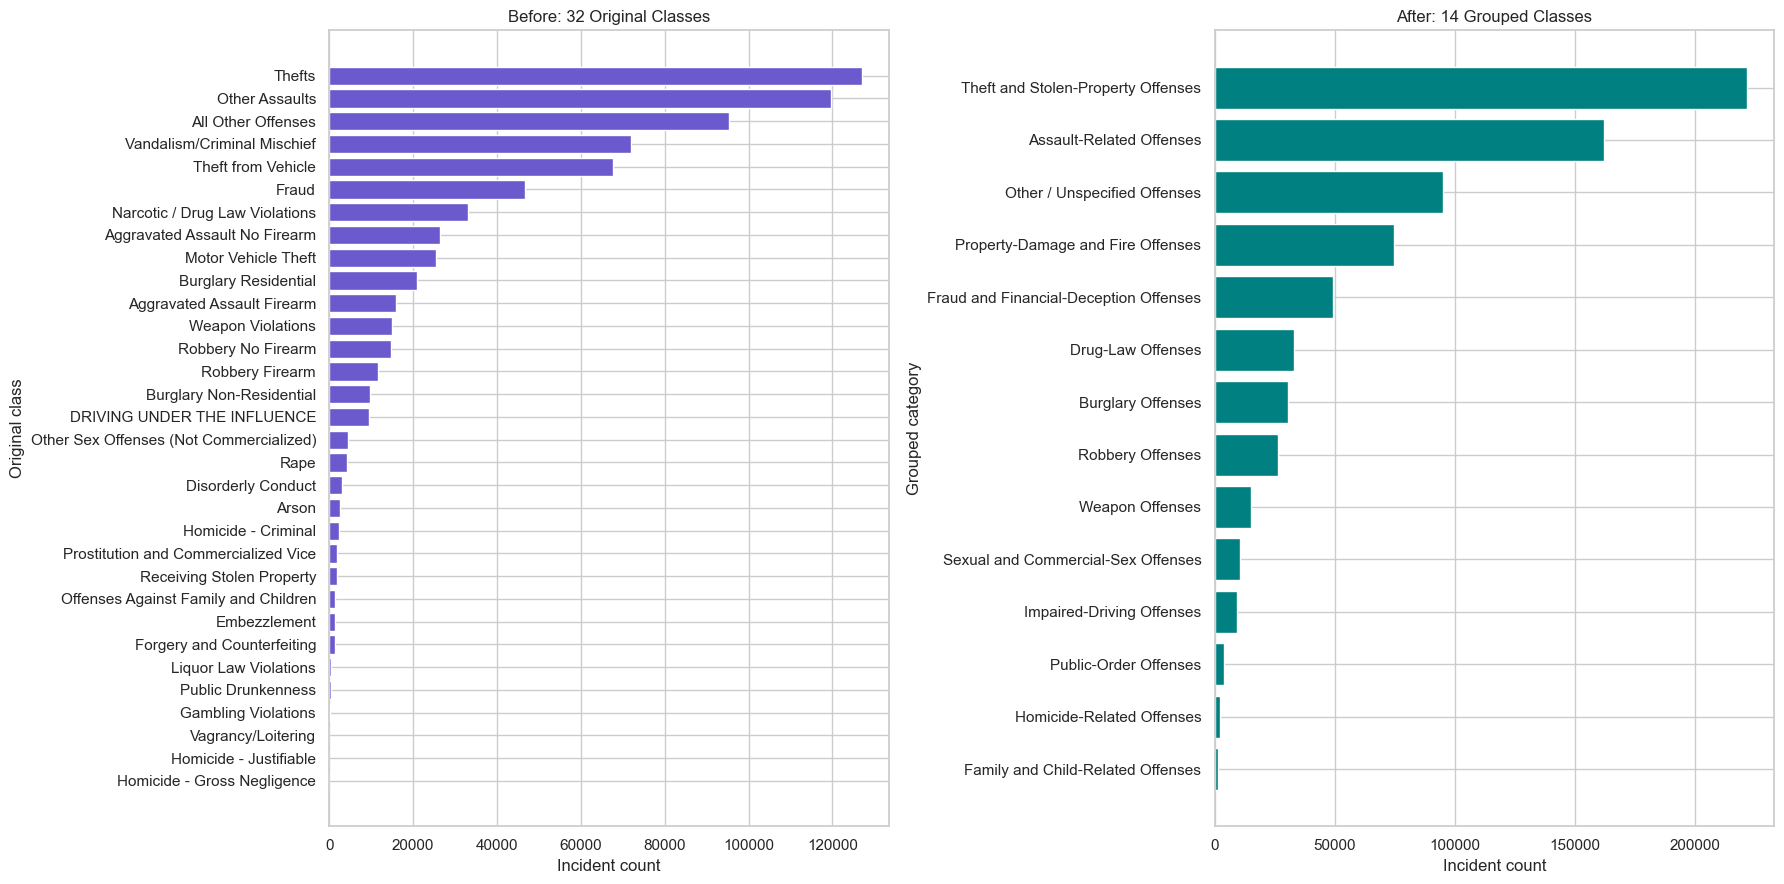

In [8]:
comparison = mapping_table[["Original Crime Type", "Original Count", "Grouped Crime Category"]].copy()
group_total_map = grouped_counts.to_dict()
comparison["Grouped Class Total Count"] = comparison["Grouped Crime Category"].map(group_total_map)
display(comparison.sort_values(["Grouped Crime Category", "Original Count"], ascending=[True, False]))

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
orig_plot = original_distribution.sort_values("Count")
axes[0].barh(orig_plot["Original Crime Type"], orig_plot["Count"], color="slateblue")
axes[0].set(title=f"Before: {df_grouped[target].nunique()} Original Classes", xlabel="Incident count", ylabel="Original class")
group_plot = grouped_distribution.sort_values("Count")
axes[1].barh(group_plot["Grouped Crime Category"], group_plot["Count"], color="teal")
axes[1].set(title=f"After: {df_grouped['crime_group'].nunique()} Grouped Classes", xlabel="Incident count", ylabel="Grouped category")
plt.tight_layout(); plt.show()


## 11. Grouping Summary and Justification

The summary lists the exact source classes included in each group, the number of original classes, and the resulting record share.

In [9]:
grouping_summary = (mapping_table.groupby("Grouped Crime Category", sort=False)
    .agg(Original_Classes_Included=("Original Crime Type", lambda s: ", ".join(s)),
         Number_of_Original_Classes=("Original Crime Type", "size"),
         Total_Records=("Original Count", "sum"))
    .reset_index()
    .rename(columns={"Grouped Crime Category": "Grouped Crime Category",
                     "Original_Classes_Included": "Original Classes Included",
                     "Number_of_Original_Classes": "Number of Original Classes",
                     "Total_Records": "Total Records"}))
grouping_summary["Percentage of Dataset"] = (grouping_summary["Total Records"] / len(df) * 100).round(4)
display(grouping_summary.sort_values("Total Records", ascending=False).reset_index(drop=True))


,Grouped Crime Category,Original Classes Included,Number of Original Classes,Total Records,Percentage of Dataset
0,Theft and Stolen-Property Offenses,"Motor Vehicle Theft, Receiving Stolen Property...",4,221813,30.1363
1,Assault-Related Offenses,"Aggravated Assault Firearm, Aggravated Assault...",3,162012,22.0115
2,Other / Unspecified Offenses,All Other Offenses,1,95265,12.9430
3,Property-Damage and Fire Offenses,"Arson, Vandalism/Criminal Mischief",2,74555,10.1293
4,Fraud and Financial-Deception Offenses,"Embezzlement, Forgery and Counterfeiting, Fraud",3,49240,6.6899
5,Drug-Law Offenses,Narcotic / Drug Law Violations,1,33032,4.4878
6,Burglary Offenses,"Burglary Non-Residential, Burglary Residential",2,30742,4.1767
7,Robbery Offenses,"Robbery Firearm, Robbery No Firearm",2,26385,3.5848
8,Weapon Offenses,Weapon Violations,1,14952,2.0314
9,Sexual and Commercial-Sex Offenses,"Other Sex Offenses (Not Commercialized), Prost...",3,10752,1.4608


## Grouping Justification

Crime categories were consolidated based on semantic similarity and the nature of the recorded offense. The purpose was to reduce excessive granularity while retaining interpretable distinctions between major types of criminal activity. The grouping is explicit and reproducible, and no model performance or `ucr_general` values were used to define it. Reduced extreme class sparsity is a secondary consequence, not the primary grouping criterion.

### Verify saved artifacts without rewriting them
The semantic grouping above is checked against the committed mapping and grouped dataset. This cell is read-only.

In [10]:
saved_mapping = load_class_group_mapping()
saved_grouped = load_grouped_philadelphia_data(usecols=[TARGET_GROUPED], low_memory=False)
assert len(saved_mapping) == 32, f"Expected 32 mapping rows, found {len(saved_mapping)}"
assert len(saved_grouped) == len(df) == 736033
assert df_grouped[TARGET_GROUPED].reset_index(drop=True).equals(saved_grouped[TARGET_GROUPED].reset_index(drop=True))
print("Saved mapping and grouped data verified; no files were written.")


Saved mapping and grouped data verified; no files were written.


## 13. Final Validation and Stratified Split Feasibility

Validate the saved mapping and grouped copy, confirm no rows were lost and the original labels remain unchanged, then check whether stratified 70/30 splitting is feasible for the grouped target. No classifier is initialized or trained here.

In [11]:
saved_mapping = load_class_group_mapping()
saved_groups = load_grouped_philadelphia_data(usecols=[TARGET_GROUPED], low_memory=False)
assert len(saved_mapping) == 32
assert len(saved_groups) == 736033
assert saved_groups[TARGET_GROUPED].nunique() == 14
print("Verified saved mapping:", saved_mapping.shape)
print("Verified saved grouped target:", saved_groups[TARGET_GROUPED].value_counts().to_dict())


Verified saved mapping: (32, 4)
Verified saved grouped target: {'Theft and Stolen-Property Offenses': 221813, 'Assault-Related Offenses': 162012, 'Other / Unspecified Offenses': 95265, 'Property-Damage and Fire Offenses': 74555, 'Fraud and Financial-Deception Offenses': 49240, 'Drug-Law Offenses': 33032, 'Burglary Offenses': 30742, 'Robbery Offenses': 26385, 'Weapon Offenses': 14952, 'Sexual and Commercial-Sex Offenses': 10752, 'Impaired-Driving Offenses': 9470, 'Public-Order Offenses': 4042, 'Homicide-Related Offenses': 2287, 'Family and Child-Related Offenses': 1486}


## 14. Conclusion and Modeling Boundary

All 32 original Philadelphia crime labels have one explicit semantic mapping. The grouped analysis copy preserves every original record and target label while adding `crime_group`. The mapping table and grouped CSV are prepared for the next stage. **No models were trained**; model training and evaluation remain in the separate modeling notebook.